In [1]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from utils import fetch_df

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
%matplotlib inline

In [2]:
query_ltv = """
SELECT
    client_id,
    age,
    segment,
    tx_count,
    avg_tx_amount,
    days_since_last_tx,
    total_gmv  -- Это наш таргет (LTV)
FROM neobank_marts.dm_ltv
"""
# В витрине dm_ltv нет возраста и days_since_last_tx, поэтому присоединим профиль
# (В реальном проекте это было бы в одной витрине)
query_ltv = """
SELECT
    l.client_id,
    c.age,
    l.segment,
    l.total_tx AS tx_count,
    l.avg_check AS avg_tx_amount,
    dateDiff('day', l.last_tx_date, toDate('2024-12-31')) AS days_since_last_tx,
    l.total_gmv
FROM neobank_marts.dm_ltv l
JOIN neobank_staging.stg_clients c ON l.client_id = c.client_id
"""
df_ltv = fetch_df(query_ltv)
print(f"Загружено {len(df_ltv):,} клиентов")
df_ltv.head()

Загружено 15,343 клиентов


,client_id,age,segment,tx_count,avg_tx_amount,days_since_last_tx,total_gmv
0,34225,41,family,31,10695.645161,50,331565.0
1,8899,47,premium,11,9838.636364,225,108225.0
2,25138,45,family,5,13620.600000,87,68103.0
3,36708,38,family,4,5690.500000,39,22762.0
4,37380,36,family,4,10255.000000,26,41020.0


In [3]:
# One-Hot Encoding
df_ltv = pd.get_dummies(df_ltv, columns=["segment"], drop_first=True)

# Динамический выбор фич
features = [
    col for col in df_ltv.columns 
    if col not in ["client_id", "total_gmv"] 
    and df_ltv[col].dtype in ['int64', 'float64', 'uint8', 'bool', 'int32']
]

X = df_ltv[features]
y = df_ltv["total_gmv"]

print(f"Признаки: {features}")

Признаки: ['avg_tx_amount']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [6]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE (Средняя абсолютная ошибка): {mae:,.2f} руб.")
print(f"RMSE (Квадратичная ошибка): {rmse:,.2f} руб.")
print(f"R² (Доля объясненной дисперсии): {r2:.4f}")

MAE (Средняя абсолютная ошибка): 188,104.27 руб.
RMSE (Квадратичная ошибка): 379,819.03 руб.
R² (Доля объясненной дисперсии): 0.0461


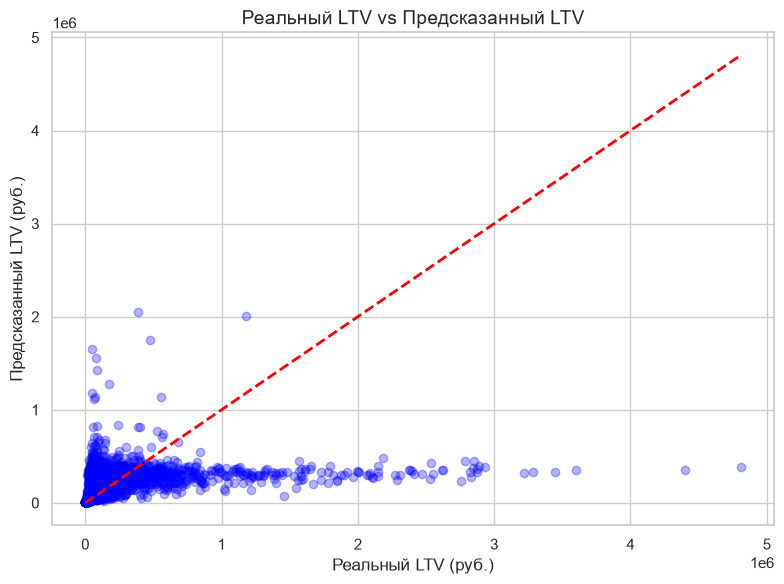

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color="blue")

# Рисуем линию идеального предсказания
max_val = max(y_test.max(), y_pred.max())
plt.plot([0, max_val], [0, max_val], color="red", linestyle="--", linewidth=2)

plt.title("Реальный LTV vs Предсказанный LTV", fontsize=14)
plt.xlabel("Реальный LTV (руб.)")
plt.ylabel("Предсказанный LTV (руб.)")
plt.tight_layout()
plt.show()

C:\Users\Dima\AppData\Local\Temp\ipykernel_17956\3114096862.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=np.array(features)[indices], palette="magma")


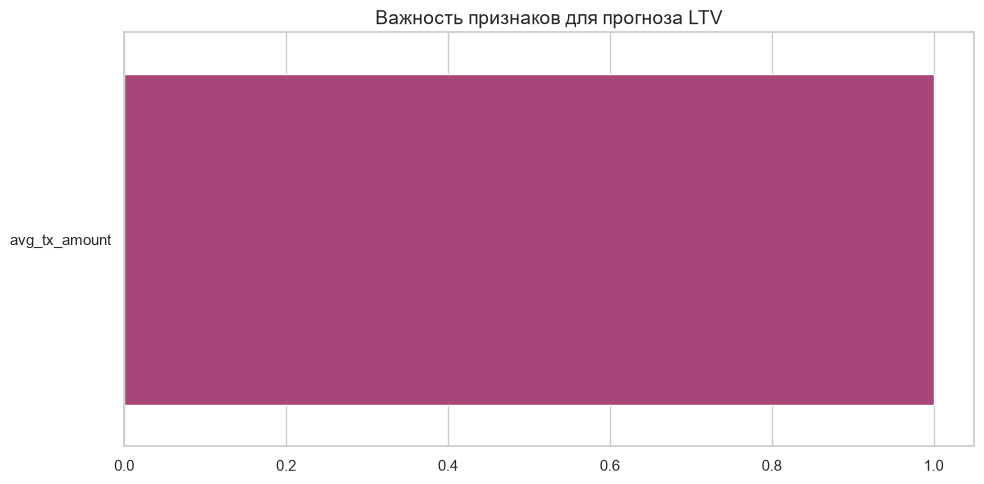

In [8]:
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[indices], y=np.array(features)[indices], palette="magma")
plt.title("Важность признаков для прогноза LTV", fontsize=14)
plt.tight_layout()
plt.show()

## 📊 Вывод по модели LTV Regression

**Бизнес-вопрос:** Сколько принесет клиент?

**Метрики:**
* **MAE:** (вставь значение). На сколько в среднем рублей мы ошибаемся.
* **R²:** (вставь значение). Если R² > 0.5 — модель хорошо объясняет данные.

**Бизнес-эффект:**
Модель позволяет нам сегментировать клиентов на этапе регистрации. 
Если модель предсказывает LTV = 5000 руб., мы можем потратить на его привлечение (CAC) не более 1500 руб. (LTV/CAC > 3).
Клиентов с предсказанным LTV ниже стоимости привлечения мы можем не привлекать или менять стратегию.